# 03 · Feature Engineering and Feature Selection
Course phase **6** (both pillars: *creation* and *selection*) · **Team T107** · Project 21

**Builds on:** `fdp.config`, `fdp.data` (01), the EDA findings (02). **Commits:** `src/fdp/features.py`, `src/fdp/selection.py`, `tests/test_leakage.py`, `reports/03_features.json`, `reports/figures/03_*.png`.

**Rule:** features may only use information known at **05:00 on day D**. Selection decisions are made on the **validation month (September)** and double-checked on **October**. The test months are never used here.


In [1]:
#@title ⚙️ 0 · Setup — run this cell first { display-mode: "form" }
#@markdown In **Colab** this clones the team repo and installs the requirements.
#@markdown Locally (Jupyter / VS Code) it just moves to the repo root.
REPO_URL = "https://github.com/mrstrange1708/T107_Flight_Delay_Prediction.git"  #@param {type:"string"}
BRANCH = "main"  #@param {type:"string"}
QUICK_RUN = False  #@param {type:"boolean"}
#@markdown `QUICK_RUN` = smaller searches/samples so the notebook finishes in a few minutes (use it to check the code runs; turn it OFF for the final numbers you commit).

import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("/content/T107_Flight_Delay_Prediction/.git"):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, "/content/T107_Flight_Delay_Prediction"], check=True)
    os.chdir("/content/T107_Flight_Delay_Prediction")
    if os.path.exists("requirements.txt"):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
for d in ["src/fdp", "tests", "data/raw", "data/processed", "reports/figures"]:
    os.makedirs(d, exist_ok=True)
open("src/fdp/__init__.py", "a").close()
sys.path.insert(0, os.path.abspath("src"))

import warnings; warnings.filterwarnings("ignore")
import json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Working directory:", os.getcwd(), "| Colab:", IN_COLAB, "| QUICK_RUN:", QUICK_RUN)

Working directory: /Users/shaikjunaidsami/Desktop/T107_Flight_Delay_Prediction | Colab: False | QUICK_RUN: False


---
## Part A · Feature creation
Raw columns correlated only weakly with the label (notebook 02). The worksheet's key insight: *good features let even a simple model do well.* We create five groups, each motivated by an EDA finding:

| Group | Features | EDA finding / domain reason |
|---|---|---|
| **schedule** | sin/cos of departure and arrival time, hour, log distance, overnight arrival | risk rises through the day; time is circular (23:59 is next to 00:00) |
| **calendar** | sin/cos day of week, weekend flag, days to nearest US federal holiday | calm Saturdays; holiday traffic peaks |
| **aircraft** | plane age, seats, engines (+ missing indicators added in preprocessing) | static facts about the aircraft |
| **congestion** | flights **scheduled** at the origin in that hour, ±1 hour, that day; carrier's flights at origin that day; NYC arrivals scheduled into the destination that hour | busy airports and banks of departures cause queues |
| **history** | smoothed delay **rate** and log **volume** over trailing windows ending on day D−1, for 12 (grouping, window) pairs over 9 groupings (all flights, carrier, origin, destination, route, carrier×origin, origin×hour, flight number, tail number); the two all-flights rates have no volume feature | "flights that were late recently tend to be late again"; lag-1 memory found in notebook 02 |

**Combining features (worksheet's interaction idea):** each history rate is shrunk towards the overall rate:

$$\text{rate}_g = \frac{k_g + \alpha\cdot \text{prior}}{n_g + \alpha}$$

where $k_g$ of $n_g$ flights in group $g$ were delayed in the window. A flight number seen 3 times with 2 delays would otherwise get 0.67, which is mostly noise. With $\alpha = 10$ pseudo-flights the small group is pulled towards the average, while big groups barely move. The volume feature ($\log(1+n_g)$, for every grouping except all flights) tells the model how much evidence each rate rests on.

**Deliberately not created:** month and day-of-year. With one year of data, November–December never appear in training, so these would act as date IDs the model cannot learn from.

In [2]:
%%writefile src/fdp/features.py
"""Phase 6 feature engineering (creation). Every feature is known at 05:00 on day D.

Groups
  schedule   : cyclic departure/arrival time, distance, overnight arrival
  calendar   : cyclic day of week, weekend, days to nearest US federal holiday
  aircraft   : plane age, seats, engines (static)
  congestion : how many flights are SCHEDULED at the origin in the hour / +-1 h / day, the carrier's
               flights at the origin that day, NYC arrivals scheduled into the destination that hour
  history    : smoothed delay rate + log volume over trailing windows that END ON DAY D-1
"""
import numpy as np
import pandas as pd
from pandas.tseries.holiday import USFederalHolidayCalendar

# (name, grouping columns, window in days). Windows come from the ACF analysis in notebook 02.
HISTORY_SPECS = [
    ("all", [], 1), ("all", [], 7),
    ("carrier", ["carrier"], 7), ("carrier", ["carrier"], 28),
    ("origin", ["origin"], 1), ("origin", ["origin"], 7),
    ("dest", ["dest"], 28), ("route", ["origin", "dest"], 28),
    ("carrier_origin", ["carrier", "origin"], 7),
    ("origin_hour", ["origin", "sched_hour"], 28),
    ("flight", ["carrier", "flight"], 28),
    ("tail", ["tailnum"], 7),
]
COLD_START_RATE = 0.20   # used only before any history exists (first days of January)


def _key(df, cols):
    if not cols:
        return pd.Series("ALL", index=df.index)
    k = df[cols[0]].astype(str)
    for c in cols[1:]:
        k = k + "|" + df[c].astype(str)
    return k


def trailing_counts(df, cols, window):
    """(delayed count, flight count) per (date, group) over the `window` days BEFORE each date.

    .rolling(window).sum() covers days [D-window+1, D]; .shift(1) moves it to [D-window, D-1],
    so outcomes of day D itself are never included. This one line is what prevents leakage.
    """
    obs = df[df["delayed"].notna()].assign(_g=lambda d: _key(d, cols))
    dates = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
    k = obs.pivot_table(index="date", columns="_g", values="delayed", aggfunc="sum", fill_value=0)
    n = obs.pivot_table(index="date", columns="_g", values="delayed", aggfunc="size", fill_value=0)
    roll = lambda m: m.reindex(dates, fill_value=0).rolling(window, min_periods=1).sum().shift(1).fillna(0)
    k, n = roll(k), roll(n)
    k.index.name = n.index.name = "date"
    return k.stack(), n.stack()


def build_features(df: pd.DataFrame, alpha: float = 10.0):
    """Return (X, groups). X = df plus feature columns; groups = {group name: [columns]}."""
    X = df.copy()
    g = {"schedule": [], "calendar": [], "aircraft": ["plane_age", "plane_seats", "plane_engines"],
         "congestion": [], "history": []}

    # schedule: time of day lives on a circle (23:59 is next to 00:00), so encode with sin/cos
    for col, name in (("sched_dep_min", "dep"), ("sched_arr_min", "arr")):
        ang = 2 * np.pi * X[col] / 1440
        X[f"{name}_sin"], X[f"{name}_cos"] = np.sin(ang), np.cos(ang)
    X["log_distance"] = np.log(X["distance"])
    X["overnight_arrival"] = (X["sched_arr_min"] < X["sched_dep_min"]).astype(int)
    g["schedule"] = ["dep_sin", "dep_cos", "arr_sin", "arr_cos", "sched_hour", "log_distance", "overnight_arrival"]

    # calendar (no month / day-of-year: test months never appear in training, so they act as date IDs)
    dow = X["date"].dt.day_of_week
    X["dow_sin"], X["dow_cos"] = np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7)
    X["is_weekend"] = (dow >= 5).astype(int)
    hol = USFederalHolidayCalendar().holidays("2012-12-01", "2014-01-31").values
    days = np.abs(X["date"].values[:, None] - hol[None, :]).min(axis=1) / np.timedelta64(1, "D")
    X["days_to_holiday"] = np.minimum(days, 14)
    g["calendar"] = ["dow_sin", "dow_cos", "is_weekend", "days_to_holiday"]

    # congestion from the published schedule (cancelled flights included: they were scheduled)
    per_hour = X.groupby(["origin", "date", "sched_hour"])["flight"].transform("size")
    X["origin_hour_sched"] = per_hour - 1
    oh = X.groupby(["origin", "date", "sched_hour"]).size()
    idx = lambda h: pd.MultiIndex.from_arrays([X["origin"], X["date"], h])
    X["origin_3h_sched"] = sum(oh.reindex(idx(X["sched_hour"] + s)).fillna(0).to_numpy() for s in (-1, 0, 1)) - 1
    X["origin_day_sched"] = X.groupby(["origin", "date"])["flight"].transform("size") - 1
    X["carrier_origin_day_sched"] = X.groupby(["carrier", "origin", "date"])["flight"].transform("size") - 1
    X["dest_arr_hour_sched"] = X.groupby(["dest", "date", "arr_hour"])["flight"].transform("size") - 1
    g["congestion"] = ["origin_hour_sched", "origin_3h_sched", "origin_day_sched", "carrier_origin_day_sched", "dest_arr_hour_sched"]

    # history: smoothed past delay rates. rate = (k + alpha * prior) / (n + alpha)
    priors = {}
    for name, cols, w in HISTORY_SPECS:
        if w not in priors:
            pk, pn = trailing_counts(df, [], w)
            priors[w] = (pk.droplevel(1) / pn.droplevel(1).replace(0, np.nan)).fillna(COLD_START_RATE)
        k, n = trailing_counts(df, cols, w)
        ix = pd.MultiIndex.from_arrays([X["date"], _key(X, cols)])
        kk = k.reindex(ix).fillna(0).to_numpy()
        nn = n.reindex(ix).fillna(0).to_numpy()
        prior = priors[w].reindex(X["date"]).fillna(COLD_START_RATE).to_numpy()
        X[f"h_{name}_{w}d_rate"] = (kk + alpha * prior) / (nn + alpha)
        g["history"].append(f"h_{name}_{w}d_rate")
        if cols:  # volume tells the model how much evidence the rate is based on
            X[f"h_{name}_{w}d_logn"] = np.log1p(nn)
            g["history"].append(f"h_{name}_{w}d_logn")
    return X, g


def numeric_columns(groups, include=("schedule", "calendar", "aircraft", "congestion", "history")):
    return [c for name in include for c in groups[name]]

Overwriting src/fdp/features.py


In [3]:
#@title 🎛️ Smoothing strength α for history rates { display-mode: "form" }
ALPHA = 10  #@param {type:"slider", min:0, max:50, step:1}
import fdp.config as config, fdp.data as data, fdp.features as features
importlib.reload(features)
df = data.build_dataset(*data.load_raw())
X, groups = features.build_features(df, alpha=ALPHA)
NUM = features.numeric_columns(groups)
pd.DataFrame({"group": list(groups), "n_features": [len(v) for v in groups.values()],
              "examples": [", ".join(v[:3]) + (" …" if len(v) > 3 else "") for v in groups.values()]})

,group,n_features,examples
0,schedule,7,"dep_sin, dep_cos, arr_sin …"
1,calendar,4,"dow_sin, dow_cos, is_weekend …"
2,aircraft,3,"plane_age, plane_seats, plane_engines"
3,congestion,5,"origin_hour_sched, origin_3h_sched, origin_day..."
4,history,22,"h_all_1d_rate, h_all_7d_rate, h_carrier_7d_rate …"


In [4]:
# One real flight, to see what the model receives at 05:00
example = X[(X["date"] == "2013-07-15") & (X["carrier"] == "UA")].iloc[0]
print(example[["date", "carrier", "flight", "origin", "dest", "sched_dep_time"]].to_string())
example[NUM].to_frame("value").T.round(3)

date              2013-07-15 00:00:00
carrier                            UA
flight                           1258
origin                            EWR
dest                              DEN
sched_dep_time                    515


,dep_sin,dep_cos,arr_sin,arr_cos,sched_hour,log_distance,overnight_arrival,dow_sin,dow_cos,is_weekend,days_to_holiday,plane_age,plane_seats,plane_engines,origin_hour_sched,...,h_origin_1d_logn,h_origin_7d_rate,h_origin_7d_logn,h_dest_28d_rate,h_dest_28d_logn,h_route_28d_rate,h_route_28d_logn,h_carrier_origin_7d_rate,h_carrier_origin_7d_logn,h_origin_hour_28d_rate,h_origin_hour_28d_logn,h_flight_28d_rate,h_flight_28d_logn,h_tail_7d_rate,h_tail_7d_logn
value,0.980785,0.19509,0.932008,-0.362438,5,7.380879,0,0.0,1.0,0,11.0,7.0,149.0,2.0,3,...,5.793014,0.365193,7.734121,0.365022,6.356108,0.402988,5.472271,0.327241,6.810142,0.107531,4.488636,0.344107,2.302585,0.341158,0.693147


### Proving there is no leakage
`trailing_counts` uses `.rolling(window).sum().shift(1)`: the rolling sum covers days [D−w+1, D] and the shift moves it to [D−w, D−1]. The test below scrambles every outcome on and after a cutoff date, rebuilds the features, and checks that the features **on the cutoff date** are bit-identical. If any feature peeked at day D, the test fails.

In [5]:
%%writefile tests/test_leakage.py
"""Leakage guard: features for day D must not change if outcomes on/after D change.
Run from the repo root:  python -m pytest -q tests"""
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))
from fdp import data, features  # noqa: E402
from fdp.config import POST_DEPARTURE_COLUMNS  # noqa: E402

CUTOFF = pd.Timestamp("2013-06-15")


def _small():
    f, p = data.load_raw()
    return data.build_dataset(f[f["month"].between(5, 7)], p)


def test_features_ignore_same_day_and_future_outcomes():
    df = _small()
    X1, g = features.build_features(df)
    scrambled = df.copy()
    future = scrambled["date"] >= CUTOFF
    rng = np.random.default_rng(0)
    for col in POST_DEPARTURE_COLUMNS:
        scrambled.loc[future, col] = rng.permutation(scrambled.loc[future, col].to_numpy())
    scrambled.loc[future, "delayed"] = 1.0 - scrambled.loc[future, "delayed"]
    X2, _ = features.build_features(scrambled)
    cols = features.numeric_columns(g)
    day = X1["date"] == CUTOFF
    pd.testing.assert_frame_equal(X1.loc[day, cols], X2.loc[day, cols])


def test_no_post_departure_column_is_a_feature():
    _, g = features.build_features(_small())
    assert not set(features.numeric_columns(g)) & set(POST_DEPARTURE_COLUMNS)

Overwriting tests/test_leakage.py


In [6]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "tests"], capture_output=True, text=True)
print(r.stdout[-400:])
leakage_tests = r.stdout.strip().splitlines()[-1]

..                                                                       [100%]
2 passed in 2.00s



### Does each group add information?
Logistic regression on numeric features, fitted on train, scored on September and October as groups are added one at a time. (Notebook 05 repeats this ablation with gradient boosting.)

In [7]:
%%writefile src/fdp/selection.py
"""Phase 6 feature selection: filter (correlation / mutual information), wrapper (SFS),
multicollinearity check (VIF), dimensionality reduction check (PCA)."""
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def vif(frame: pd.DataFrame) -> pd.Series:
    """VIF_j = 1 / (1 - R^2_j), R^2_j from regressing feature j on all the others (computed via the
    inverse correlation matrix: VIF_j is its j-th diagonal element)."""
    corr = np.corrcoef(frame.to_numpy(dtype=float), rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(corr)), index=frame.columns)


def vif_prune(frame: pd.DataFrame, limit: float = 10.0):
    """Repeatedly drop the highest-VIF feature until every VIF <= limit."""
    kept, dropped = list(frame.columns), []
    while True:
        v = vif(frame[kept])
        if v.max() <= limit:
            return kept, dropped
        worst = v.idxmax()
        dropped.append((worst, float(v.max())))
        kept.remove(worst)


def lr_score(Xtr, ytr, Xva, yva, cols, C=1.0):
    m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    m.fit(Xtr[cols], ytr)
    return float(average_precision_score(yva, m.predict_proba(Xva[cols])[:, 1]))


def sequential_forward_selection(Xtr, ytr, Xva, yva, candidates, max_features=15, verbose=True):
    """Wrapper method: start empty, add the feature that most improves validation PR AUC."""
    selected, remaining, path = [], list(candidates), []
    for step in range(max_features):
        scores = {f: lr_score(Xtr, ytr, Xva, yva, selected + [f]) for f in remaining}
        best = max(scores, key=scores.get)
        selected.append(best)
        remaining.remove(best)
        path.append({"step": step + 1, "added": best, "valid_pr_auc": scores[best]})
        if verbose:
            print(f"step {step + 1:2d}: + {best:<28s} valid PR AUC {scores[best]:.4f}")
    return path

Overwriting src/fdp/selection.py


In [8]:
import fdp.selection as sel; importlib.reload(sel)
S = data.split(X)
med = S["train"][NUM].median()
A = {k: v[NUM].fillna(med) for k, v in S.items()}         # medians from TRAIN only
y = {k: v["delayed"].astype(int).to_numpy() for k, v in S.items()}
order = ["schedule", "calendar", "aircraft", "congestion", "history"]
rows, cols = [], []
for gname in order:
    cols = cols + groups[gname]
    rows.append({"features": " + ".join(order[:order.index(gname) + 1]), "n": len(cols),
                 "valid_pr_auc": round(sel.lr_score(A["train"], y["train"], A["valid"], y["valid"], cols), 4),
                 "calib_pr_auc": round(sel.lr_score(A["train"], y["train"], A["calib"], y["calib"], cols), 4)})
group_table = pd.DataFrame(rows)
group_table

,features,n,valid_pr_auc,calib_pr_auc
0,schedule,7,0.1918,0.2363
1,schedule + calendar,11,0.2055,0.2727
2,schedule + calendar + aircraft,14,0.2027,0.2786
3,schedule + calendar + aircraft + congestion,19,0.2095,0.3044
4,schedule + calendar + aircraft + congestion + ...,41,0.2610,0.3065


Read both columns (random guessing scores the base rate: September 0.137, October 0.176):
* Every group helps somewhere, and **all five together are best on both months**.
* **History** gives the biggest jump in September but adds little in October, where **calendar** and **congestion** add more. For a linear model, which group matters depends on the month.
* That is a warning against judging features on one month. Notebook 05 repeats this ablation with gradient boosting on three rolling months.

---
## Part B · Feature selection
The worksheet lists **filter** and **embedded** methods; the syllabus adds **wrapper** methods (sequential forward selection), **VIF** for multicollinearity and **PCA** for dimensionality reduction. We try each and keep a method only if it improves **both** held-out months.

### B1 · Filter methods: correlation and mutual information

In [9]:
from sklearn.feature_selection import mutual_info_classif
rng = np.random.default_rng(config.SEED)
idx = rng.choice(len(A["train"]), 30000, replace=False)
mi = pd.Series(mutual_info_classif(A["train"].iloc[idx], y["train"][idx], random_state=config.SEED), index=NUM).sort_values(ascending=False)
pear = A["train"].corrwith(pd.Series(y["train"], index=A["train"].index)).abs().sort_values(ascending=False)
filt = []
for k in (5, 10, 20, 30, len(NUM)):
    top = list(mi.index[:k])
    filt.append({"top_k_by_MI": k, "valid_pr_auc": round(sel.lr_score(A["train"], y["train"], A["valid"], y["valid"], top), 4),
                 "calib_pr_auc": round(sel.lr_score(A["train"], y["train"], A["calib"], y["calib"], top), 4)})
display(pd.DataFrame({"mutual_info": mi.head(10).round(4), "abs_pearson": pear.reindex(mi.head(10).index).round(4)}))
filter_table = pd.DataFrame(filt); filter_table

,mutual_info,abs_pearson
h_origin_hour_28d_rate,0.0921,0.2312
h_carrier_7d_rate,0.0757,0.1215
h_carrier_origin_7d_rate,0.0732,0.1278
h_carrier_28d_rate,0.0716,0.1241
h_origin_7d_rate,0.0598,0.0619
h_origin_1d_rate,0.0578,0.1270
h_all_1d_rate,0.0528,0.1196
h_dest_28d_rate,0.0522,0.0980
h_all_7d_rate,0.0505,0.0461
h_carrier_28d_logn,0.0494,0.0123


,top_k_by_MI,valid_pr_auc,calib_pr_auc
0,5,0.1869,0.2732
1,10,0.2396,0.2634
2,20,0.2506,0.2793
3,30,0.2559,0.2990
4,41,0.2610,0.3065


Mutual information ranks the history rates highest. Keeping only the top-k never beats keeping all features on both months, so the filter is used for **insight, not for dropping features**.

### B2 · Multicollinearity: VIF

In [10]:
samp = A["train"].iloc[idx]
samp = samp.loc[:, samp.std() > 0]
v = sel.vif(samp).sort_values(ascending=False)
kept, dropped = sel.vif_prune(samp, limit=10)
vif_result = {"n_above_10": int((v > 10).sum()), "top5": v.head(5).round(1).to_dict(), "dropped": [(a, round(b, 1)) for a, b in dropped],
              "valid_all": round(sel.lr_score(A["train"], y["train"], A["valid"], y["valid"], NUM), 4),
              "valid_after_vif": round(sel.lr_score(A["train"], y["train"], A["valid"], y["valid"], kept), 4),
              "calib_all": round(sel.lr_score(A["train"], y["train"], A["calib"], y["calib"], NUM), 4),
              "calib_after_vif": round(sel.lr_score(A["train"], y["train"], A["calib"], y["calib"], kept), 4)}
vif_result

{'n_above_10': 13,
 'top5': {'h_carrier_7d_logn': 67.2,
  'h_carrier_28d_logn': 66.3,
  'dep_sin': 55.4,
  'arr_cos': 37.5,
  'sched_hour': 24.3},
 'dropped': [('h_carrier_7d_logn', 67.2),
  ('dep_sin', 55.4),
  ('arr_cos', 20.8),
  ('sched_hour', 14.6),
  ('h_carrier_7d_rate', 14.2),
  ('carrier_origin_day_sched', 11.2),
  ('h_origin_7d_rate', 11.2)],
 'valid_all': 0.261,
 'valid_after_vif': 0.2558,
 'calib_all': 0.3065,
 'calib_after_vif': 0.3016}

$\text{VIF}_j = 1/(1-R^2_j)$, where $R^2_j$ comes from regressing feature $j$ on all the others; above 10 means feature $j$ is mostly predictable from the rest. High VIFs come from pairs that share information (sin/cos time pairs, carrier 7-day vs 28-day volume). Collinearity makes **linear coefficients unstable to interpret**, but it does not hurt **prediction**, and gradient boosting is unaffected. Removing these features lowers the held-out score, so we **report VIF but keep the features**; logistic regression's L2 penalty (notebook 04) stabilises its weights.

### B3 · Wrapper method: Sequential Forward Selection (a simple loop in `selection.py`)

In [11]:
#@title 🎛️ SFS settings { display-mode: "form" }
SFS_MAX_FEATURES = 12  #@param {type:"slider", min:3, max:20, step:1}
SFS_SAMPLE = 60000  #@param {type:"integer"}
if QUICK_RUN:
    SFS_MAX_FEATURES, SFS_SAMPLE = 5, 20000
sub = rng.choice(len(A["train"]), SFS_SAMPLE, replace=False)
path = sel.sequential_forward_selection(A["train"].iloc[sub], y["train"][sub], A["valid"], y["valid"], NUM, SFS_MAX_FEATURES)
best_k = max(path, key=lambda r: r["valid_pr_auc"])["step"]
sfs_cols = [p["added"] for p in path[:best_k]]
sfs_result = {"best_k": best_k, "selected": sfs_cols,
              "valid_sfs": round(sel.lr_score(A["train"], y["train"], A["valid"], y["valid"], sfs_cols), 4),
              "calib_sfs": round(sel.lr_score(A["train"], y["train"], A["calib"], y["calib"], sfs_cols), 4),
              "valid_all": vif_result["valid_all"], "calib_all": vif_result["calib_all"]}
sfs_result

step  1: + h_origin_1d_rate             valid PR AUC 0.2085


step  2: + dep_sin                      valid PR AUC 0.2464


step  3: + origin_day_sched             valid PR AUC 0.2564


step  4: + h_origin_1d_logn             valid PR AUC 0.2642


step  5: + dow_cos                      valid PR AUC 0.2679


...

step  9: + overnight_arrival            valid PR AUC 0.2728


step 10: + log_distance                 valid PR AUC 0.2736


step 11: + h_origin_7d_rate             valid PR AUC 0.2741


step 12: + h_route_28d_rate             valid PR AUC 0.2777


{'best_k': 12,
 'selected': ['h_origin_1d_rate',
  'dep_sin',
  'origin_day_sched',
  'h_origin_1d_logn',
  'dow_cos',
  'plane_age',
  'days_to_holiday',
  'is_weekend',
  'overnight_arrival',
  'log_distance',
  'h_origin_7d_rate',
  'h_route_28d_rate'],
 'valid_sfs': 0.2789,
 'calib_sfs': 0.2812,
 'valid_all': 0.261,
 'calib_all': 0.3065}

**Watch the two months.** SFS chooses features by their September score, so it naturally looks good on September. October is the honest check: if the SFS subset scores below *all features* there, SFS has over-fitted the month it was selected on. That is the classic risk of wrapper methods, which make hundreds of comparisons on one validation set.

### B4 · Embedded method: L1 (Lasso) logistic regression

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score
emb = []
for C in (0.0005, 0.002, 0.01, 0.1):
    m = make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", C=C, solver="liblinear", max_iter=3000)).fit(A["train"], y["train"])
    coef = m[-1].coef_[0]
    emb.append({"C": C, "nonzero": int((np.abs(coef) > 1e-6).sum()),
                "valid_pr_auc": round(average_precision_score(y["valid"], m.decision_function(A["valid"])), 4),
                "calib_pr_auc": round(average_precision_score(y["calib"], m.decision_function(A["calib"])), 4)})
    if C == 0.002:
        l1_kept = [NUM[i] for i in np.where(np.abs(coef) > 1e-6)[0]]
embedded_table = pd.DataFrame(emb); embedded_table

,C,nonzero,valid_pr_auc,calib_pr_auc
0,0.0005,10,0.2414,0.2911
1,0.0020,25,0.2569,0.3020
2,0.0100,36,0.2616,0.3055
3,0.1000,41,0.2611,0.3064


L1's penalty pushes weak weights to exactly zero, so selection happens *during* training. Stronger penalties (small C) keep fewer features. Notebook 05 adds the tree-based embedded method (gradient boosting feature importance).

### B5 · Dimensionality reduction: PCA

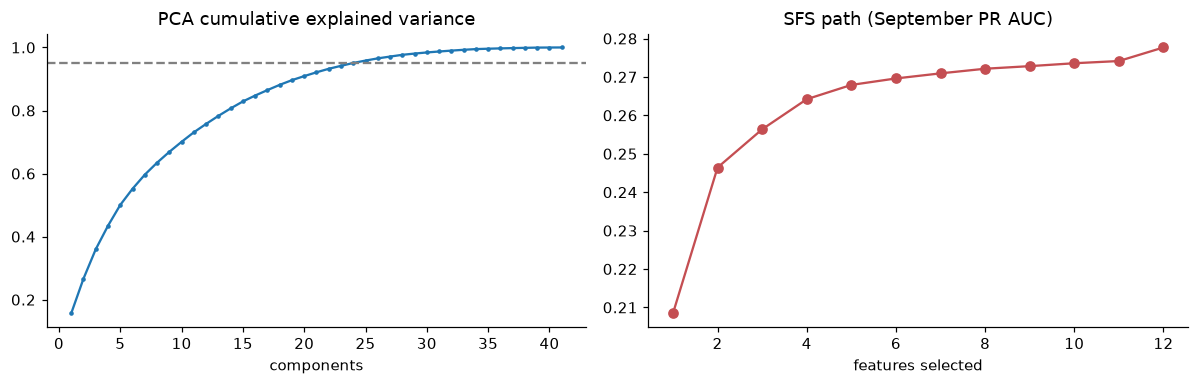

,components,variance_kept,valid_pr_auc,calib_pr_auc
0,5,0.501,0.1928,0.2837
1,10,0.701,0.2225,0.2840
2,20,0.909,0.2504,0.2803
3,24,0.951,0.2677,0.2919
4,41,1.000,0.2608,0.3065


In [13]:
from sklearn.decomposition import PCA
sc = StandardScaler().fit(A["train"])
pca = PCA().fit(sc.transform(A["train"]))
cum = np.cumsum(pca.explained_variance_ratio_)
k95 = int(np.searchsorted(cum, 0.95) + 1)
pca_rows = []
for k in (5, 10, 20, k95, len(NUM)):
    P = PCA(k, random_state=config.SEED).fit(sc.transform(A["train"]))
    m = LogisticRegression(max_iter=3000).fit(P.transform(sc.transform(A["train"])), y["train"])
    sc_ = lambda part: round(average_precision_score(y[part], m.predict_proba(P.transform(sc.transform(A[part])))[:, 1]), 4)
    pca_rows.append({"components": k, "variance_kept": round(float(cum[k - 1]), 3), "valid_pr_auc": sc_("valid"), "calib_pr_auc": sc_("calib")})
pca_table = pd.DataFrame(pca_rows)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(range(1, len(cum) + 1), cum, marker=".", ms=4); ax[0].axhline(.95, ls="--", color="grey"); ax[0].set(title="PCA cumulative explained variance", xlabel="components")
ax[1].plot([p["step"] for p in path], [p["valid_pr_auc"] for p in path], marker="o", color="#C44E52"); ax[1].set(title="SFS path (September PR AUC)", xlabel="features selected")
fig.tight_layout(); fig.savefig("reports/figures/03_pca_sfs.png"); plt.show()
pca_table

PCA mixes all features into components, so we lose the ability to say *which* information drives a prediction, and boosting gains nothing from rotated inputs. It is kept only if it clearly wins on both months.

---
## Decision

In [14]:
decision = pd.DataFrame([
    {"method": "all features", "n": len(NUM), "valid": vif_result["valid_all"], "calib": vif_result["calib_all"]},
    {"method": "filter: top 10 by MI", "n": 10, "valid": filter_table.loc[filter_table.top_k_by_MI == 10, "valid_pr_auc"].item(), "calib": filter_table.loc[filter_table.top_k_by_MI == 10, "calib_pr_auc"].item()},
    {"method": "VIF pruning (<= 10)", "n": len(kept), "valid": vif_result["valid_after_vif"], "calib": vif_result["calib_after_vif"]},
    {"method": f"wrapper: SFS ({best_k})", "n": best_k, "valid": sfs_result["valid_sfs"], "calib": sfs_result["calib_sfs"]},
    {"method": "embedded: L1, C=0.002", "n": len(l1_kept), "valid": embedded_table.loc[embedded_table.C == 0.002, "valid_pr_auc"].item(), "calib": embedded_table.loc[embedded_table.C == 0.002, "calib_pr_auc"].item()},
    {"method": f"PCA ({k95} comps, 95% var)", "n": k95, "valid": pca_table.loc[pca_table.components == k95, "valid_pr_auc"].item(), "calib": pca_table.loc[pca_table.components == k95, "calib_pr_auc"].item()},
])
decision["beats_all_on_both"] = (decision["valid"] > decision.loc[0, "valid"]) & (decision["calib"] > decision.loc[0, "calib"])
decision

,method,n,valid,calib,beats_all_on_both
0,all features,41,0.2610,0.3065,False
1,filter: top 10 by MI,10,0.2396,0.2634,False
2,VIF pruning (<= 10),34,0.2558,0.3016,False
3,wrapper: SFS (12),12,0.2789,0.2812,False
4,"embedded: L1, C=0.002",25,0.2569,0.3020,False
5,"PCA (24 comps, 95% var)",24,0.2677,0.2919,False


**We keep all features** (plus the three categorical columns) unless a method beats them on **both** held-out months. Gradient boosting chooses its own splits and ignores weak features, so an extra weak feature costs little while a wrongly dropped one loses information for good.

**Why looking at October here is safe:** October can only *veto* dropping features; the default (keep all) needs no score to justify it. October never picks a feature, a hyper-parameter or a threshold, so it stays usable for calibration in notebook 05.

In [15]:
out = {"alpha": ALPHA, "n_numeric": len(NUM), "groups": {k: v for k, v in groups.items()}, "leakage_tests": leakage_tests,
       "group_table": group_table.to_dict(orient="records"), "mutual_info_top10": mi.head(10).round(4).to_dict(),
       "filter_table": filter_table.to_dict(orient="records"), "vif": vif_result, "sfs": sfs_result, "sfs_path": path,
       "embedded_l1": embedded_table.to_dict(orient="records"), "l1_kept_at_C0.002": l1_kept,
       "pca_table": pca_table.to_dict(orient="records"), "pca_k95": k95, "decision": decision.to_dict(orient="records")}
with open("reports/03_features.json", "w") as f:
    json.dump(out, f, indent=2, default=float)
print("saved reports/03_features.json")

saved reports/03_features.json


---
## Summary
* 41 numeric features in five groups + 3 categoricals, all known at 05:00; leakage test passes.
* All five groups together score best on both held-out months; which single group matters most changes from month to month.
* Filter, VIF, SFS, L1 and PCA were each tried; none beat "all features" on both held-out months, so all features go forward.

**Next:** notebook 04 sets the baselines and compares model families.

<details><summary><b>Viva questions for this notebook (click)</b></summary>

1. **Explain `.shift(1)` in `trailing_counts`.** The rolling sum covers day D and the w−1 days before it; shifting by one day makes it cover only days before D, so the target day's outcomes never enter.
2. **Why smooth the rates?** Small groups give extreme, noisy rates; α pseudo-flights at the overall rate pull them towards the average.
3. **Why sin/cos?** Time and weekday are circular; sin/cos keeps 23:00 next to 00:00 and Sunday next to Monday.
4. **Why no month feature?** Test months never appear in training; month would act as a date ID.
5. **Define VIF. Why keep high-VIF features?** VIF = 1/(1−R²). Collinearity hurts coefficient interpretation, not prediction; dropping lowered the held-out score.
6. **Filter vs wrapper vs embedded?** Filter scores features alone before training (MI); wrapper searches subsets using a model's validation score (SFS); embedded selects during training (L1, tree importance).
7. **Why check October as well as September?** SFS picks features by September's score, so September is no longer an honest estimate; October shows whether the choice generalises.
8. **Why not PCA?** It loses interpretability, boosting gains nothing from rotated inputs, and it did not win on both months.
</details>

In [16]:
#@title 📦 Last step · download the files you must commit { display-mode: "form" }
#@markdown Downloads a zip with your module(s) and results. Also do **File → Download → Download .ipynb** (keeps the outputs).
#@markdown Unzip both into your local clone of the repo and commit them.
import glob, zipfile
FILES = [
    'src/fdp/features.py',
    'src/fdp/selection.py',
    'tests/test_leakage.py',
    'reports/03_features.json',
    'reports/figures/03_*.png',
]
paths = sorted({p for pattern in FILES for p in glob.glob(pattern)})
zip_name = "03_outputs.zip"
with zipfile.ZipFile(zip_name, "w") as z:
    for p in paths:
        z.write(p)
print("Packed", len(paths), "files into", zip_name)
for p in paths:
    print("  ", p)
if IN_COLAB:
    from google.colab import files
    files.download(zip_name)

Packed 5 files into 03_outputs.zip
   reports/03_features.json
   reports/figures/03_pca_sfs.png
   src/fdp/features.py
   src/fdp/selection.py
   tests/test_leakage.py
